# Designing a Heat Sink with a Surrogate Model

Run it top to bottom. Every figure is produced here and saved in `images/`.

**The simulator:** a 3D finite-volume conduction model of an aluminium plate-fin heat sink
cooled by a fan, with convection from a published laminar channel-flow correlation
(Teertstra et al. 1999) and the fan/duct operating point solved from the pressure balance.
It is verified against classical fin theory before we trust it.

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# Scikit-Learn ≥1.0 is required
import sklearn
assert sklearn.__version__ >= "1.0"

# Common imports
import os
import time
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

# Where to save the figures and the simulation runs
PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
DATA_PATH = os.path.join(PROJECT_ROOT_DIR, "datasets")
os.makedirs(IMAGES_PATH, exist_ok=True)
os.makedirs(DATA_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

In [2]:
# The simulator is deterministic, so Scikit-Learn's GP often reports that the noise level
# hit its lower bound. That's expected: let's silence those warnings.
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## The Problem and Its Physics

In [3]:
# The fixed part of the problem (SI units)
W = 0.060           # heat sink width (m), across the fins
L = 0.060           # heat sink depth (m), in the direction of the air flow
CHIP = 0.020        # the chip is a 20 mm x 20 mm square, centred under the base
Q = 100.0           # heat dissipated by the chip (W)
T_AIR = 35.0        # air temperature inside the case (°C)
T_MAX = 85.0        # maximum allowed chip-base temperature (°C)
R_MAX = (T_MAX - T_AIR) / Q   # so the thermal resistance must stay below 0.5 K/W

K_AL, RHO_AL = 200.0, 2700.0                 # aluminium 6063: conductivity, density
K_AIR, NU_AIR, PR_AIR = 0.0268, 1.65e-5, 0.71  # air at ~35°C
RHO_AIR, CP_AIR = 1.145, 1007.0
FAN_P0, FAN_VMAX = 50.0, 0.012               # fan: 50 Pa at zero flow, 0.012 m³/s free flow
print(f"R_max = {R_MAX:.2f} K/W")

R_max = 0.50 K/W


In [4]:
from scipy.optimize import brentq

def fin_spacing(N, t):
    return (W - N * t) / (N - 1)

def channel_flow(N, H, t):
    """Air flow through the fin channels: returns the operating point of the fan
    (approach velocity U, pressure drop dp) and the heat transfer coefficient h."""
    s = fin_spacing(N, t)
    sigma = 1 - N * t / W                    # fraction of the frontal area that is open
    Dh = 2 * s                               # hydraulic diameter of a wide channel

    def duct_dp(U):                          # pressure drop through the fins
        Uc = U / sigma                       # velocity inside the channels
        Re = Uc * Dh / NU_AIR
        L_star = L / (Dh * Re)               # developing laminar flow (Muzychka & Yovanovich)
        f_app = np.sqrt((3.44 / np.sqrt(L_star)) ** 2 + 24 ** 2) / Re
        K_c, K_e = 0.42 * (1 - sigma ** 2), (1 - sigma ** 2) ** 2   # entrance, exit losses
        return (4 * f_app * L / Dh + K_c + K_e) * 0.5 * RHO_AIR * Uc ** 2

    def fan_dp(U):                           # linear fan curve
        return FAN_P0 * (1 - U * W * H / FAN_VMAX)

    U = brentq(lambda U: duct_dp(U) - fan_dp(U), 1e-6, FAN_VMAX / (W * H) * (1 - 1e-9))
    # Teertstra et al. (1999): average Nusselt number of a plate-fin channel
    Re_s = (U / sigma) * s / NU_AIR * (s / L)
    Nu = ((Re_s * PR_AIR / 2) ** -3
          + (0.664 * np.sqrt(Re_s) * PR_AIR ** (1 / 3) * np.sqrt(1 + 3.65 / np.sqrt(Re_s))) ** -3) ** (-1 / 3)
    h = Nu * K_AIR / s
    return dict(s=s, U=U, dp=duct_dp(U), h=h, Re=U / sigma * Dh / NU_AIR, mdot=RHO_AIR * U * W * H)

flow = channel_flow(N=20, H=0.030, t=0.001)
{k: round(v, 4) for k, v in flow.items()}

{'s': 0.0021,
 'U': 2.9399,
 'dp': np.float64(27.9508),
 'h': np.float64(43.4119),
 'Re': 1125.3162,
 'mdot': 0.0061}

In [5]:
def fin_theory(N, H, t, b):
    """Low-fidelity model: textbook 1D fin theory (uniform base temperature, no spreading)."""
    f = channel_flow(N, H, t)
    h = f["h"]
    m = np.sqrt(2 * h / (K_AL * t))
    Hc = H + t / 2                                   # corrected length (convecting tip)
    eta = np.tanh(m * Hc) / (m * Hc)                 # fin efficiency
    A_fins = N * 2 * Hc * L
    A_base = (W - N * t) * L
    R_base = b / (K_AL * W * L)                      # 1D conduction through the base
    R_conv = 1 / (h * (eta * A_fins + A_base))       # fins + exposed base, in parallel
    R_air = 1 / (2 * f["mdot"] * CP_AIR)             # the air warms up as it flows through
    return R_base + R_conv + R_air

fin_theory(N=20, H=0.030, t=0.001, b=0.005)

np.float64(0.4321133361586949)

In [6]:
import scipy.sparse as sp
import scipy.sparse.linalg as spla

def heat_sink_sim(N, H, t, b, chip=CHIP, nf=2, ng=3, nb=6, nh=16, nz=24, full_output=False):
    """High-fidelity model: 3D steady heat conduction in the heat sink, discretized with the
    finite-volume method. Returns the thermal resistance R = (T_max - T_air) / Q in K/W."""
    N = int(round(N))
    f = channel_flow(N, H, t)
    s, h = f["s"], f["h"]
    # 1. The grid: nf cells across each fin, ng across each gap, nb in the base, nh along the fins
    xe = [0.0]
    for i in range(N):
        xe += list(xe[-1] + np.linspace(0, t, nf + 1)[1:])
        if i < N - 1:
            xe += list(xe[-1] + np.linspace(0, s, ng + 1)[1:])
    xe = np.array(xe)
    ye = np.concatenate([np.linspace(0, b, nb + 1), b + np.linspace(0, H, nh + 1)[1:]])
    ze = np.linspace(0, L, nz + 1)
    dx, dy, dz = np.diff(xe), np.diff(ye), np.diff(ze)
    in_fin = np.zeros(len(dx), bool)
    for i in range(N):
        in_fin[i * (nf + ng): i * (nf + ng) + nf] = True
    solid = np.zeros((len(dy), len(dz), len(dx)), bool)     # axes: (y, z, x)
    solid[:nb] = True                                        # the base is solid everywhere
    solid[nb:, :, in_fin] = True                             # above it, only the fins
    idx = -np.ones(solid.shape, int)
    idx[solid] = np.arange(solid.sum())
    n = int(solid.sum())
    DY, DZ, DX = np.meshgrid(dy, dz, dx, indexing="ij")
    D, AREA = (DY, DZ, DX), (DX * DZ, DX * DY, DY * DZ)

    # 2. The energy balance of every cell: sum of conductances x temperature differences = source
    rows, cols, vals, diag = [], [], [], np.zeros(n)
    def conv(A, d):                          # half a cell of conduction + convection, in series
        return 1 / (1 / (h * A) + d / (2 * K_AL * A))
    for axis in range(3):
        lo = [slice(None)] * 3; hi = [slice(None)] * 3
        lo[axis] = slice(0, -1); hi[axis] = slice(1, None)
        lo, hi = tuple(lo), tuple(hi)
        a, c = solid[lo], solid[hi]
        both = a & c                         # solid next to solid: conduction
        g = (K_AL * AREA[axis][lo] / ((D[axis][lo] + D[axis][hi]) / 2))[both]
        p, q = idx[lo][both], idx[hi][both]
        rows += [p, q]; cols += [q, p]; vals += [-g, -g]
        np.add.at(diag, p, g); np.add.at(diag, q, g)
        if axis == 1:
            continue                         # front and back faces: no heat loss
        for side, mask in ((lo, a & ~c), (hi, c & ~a)):   # solid next to air: convection
            np.add.at(diag, idx[side][mask], conv(AREA[axis][side][mask], D[axis][side][mask]))
    for side in (0, -1):                     # the outer faces of the first and last fins
        face = solid[nb:, :, side]
        np.add.at(diag, idx[nb:, :, side][face], conv(AREA[2][nb:, :, side][face], D[2][nb:, :, side][face]))
    top = solid[-1]                          # fin tips
    np.add.at(diag, idx[-1][top], conv(AREA[0][-1][top], D[0][-1][top]))

    # 3. The heat source: the chip's heat flux enters the bottom cells it covers
    c0, c1 = (W - chip) / 2, (W + chip) / 2
    ovx = np.clip(np.minimum(xe[1:], c1) - np.maximum(xe[:-1], c0), 0, None)
    ovz = np.clip(np.minimum(ze[1:], c1) - np.maximum(ze[:-1], c0), 0, None)
    rhs = np.zeros(n)
    rhs[idx[0].ravel()] = (Q / chip ** 2 * np.outer(ovz, ovx)).ravel()

    # 4. Solve the sparse linear system  G θ = q  (θ = T - T_air_mean)
    G = sp.csr_matrix((np.concatenate(vals + [diag]),
                       (np.concatenate(rows + [np.arange(n)]), np.concatenate(cols + [np.arange(n)]))),
                      shape=(n, n))
    theta = spla.spsolve(G.tocsc(), rhs)
    under_chip = np.outer(ovz > 0, ovx > 0)
    R = theta[idx[0][under_chip]].max() / Q + 1 / (2 * f["mdot"] * CP_AIR)
    if full_output:
        return R, dict(xe=xe, ye=ye, ze=ze, solid=solid, idx=idx, theta=theta, n=n, **f)
    return R

t0 = time.time()
R = heat_sink_sim(N=20, H=0.030, t=0.001, b=0.005)
print(f"R = {R:.4f} K/W, chip at {T_AIR + Q * R:.1f} °C ({time.time() - t0:.2f} s)")

R = 0.5640 K/W, chip at 91.4 °C (0.34 s)


## Verify the Simulator

In [7]:
# Test 1: heat the whole base uniformly (no spreading), with a thin base:
# fin theory's assumptions hold, so both models should agree.
designs = [(8, 0.020, 0.002, 0.002), (15, 0.035, 0.001, 0.002), (25, 0.045, 0.0008, 0.002)]
for N_, H_, t_, b_ in designs:
    r3d = heat_sink_sim(N_, H_, t_, b_, chip=W)
    r1d = fin_theory(N_, H_, t_, b_)
    print(f"N={N_:2d} H={H_*1e3:.0f}mm t={t_*1e3:.1f}mm: "
          f"3D {r3d:.4f}  1D {r1d:.4f}  difference {100 * (r3d / r1d - 1):+.1f}%")

N= 8 H=20mm t=2.0mm: 3D 1.0481  1D 1.0349  difference +1.3%


N=15 H=35mm t=1.0mm: 3D 0.4793  1D 0.4725  difference +1.4%


N=25 H=45mm t=0.8mm: 3D 0.3283  1D 0.3252  difference +1.0%


In [8]:
# Test 2: grid convergence. Refine all grid directions together and watch R converge.
levels = [dict(nf=1, ng=1, nb=2, nh=4, nz=8), dict(nf=1, ng=2, nb=4, nh=8, nz=12),
          dict(nf=2, ng=3, nb=6, nh=16, nz=24), dict(nf=3, ng=4, nb=9, nh=24, nz=36),
          dict(nf=4, ng=5, nb=12, nh=32, nz=48)]
grid_rows = []
for lv in levels:
    t0 = time.time()
    r, info = heat_sink_sim(16, 0.045, 0.0015, 0.008, full_output=True, **lv)
    grid_rows.append(dict(cells=info["n"], R=r, seconds=time.time() - t0))
grid = pd.DataFrame(grid_rows)
grid["error_vs_finest_%"] = 100 * (grid.R / grid.R.iloc[-1] - 1)
grid.round(4)

,cells,R,seconds,error_vs_finest_%
0,1008,0.4838,0.0036,-3.2872
1,3744,0.4939,0.0148,-1.2698
2,23376,0.4970,0.2749,-0.6492
3,76464,0.4992,2.0547,-0.2236
4,178368,0.5003,19.1044,0.0000


Saving figure grid_convergence_plot


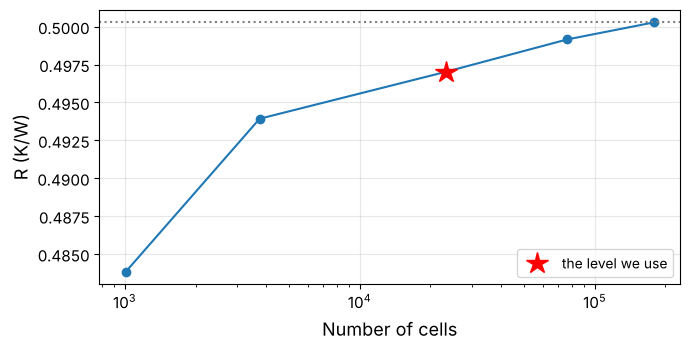

In [9]:
plt.figure(figsize=(7, 3.6))
plt.semilogx(grid.cells, grid.R, "o-")
plt.axhline(grid.R.iloc[-1], color="gray", ls=":")
plt.plot(grid.cells[2], grid.R[2], "r*", ms=16, label="the level we use")
plt.xlabel("Number of cells")
plt.ylabel("R (K/W)")
plt.legend()
plt.grid(True, alpha=0.3)
save_fig("grid_convergence_plot")
plt.show()

Saving figure temperature_field_plot


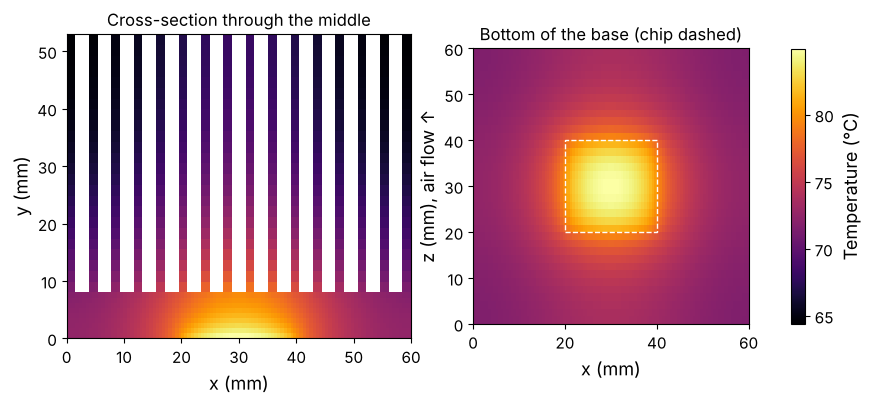

Fin tips: from 64.4 °C (outer fins) to 68.0 °C (above the chip)


In [10]:
R_demo, info = heat_sink_sim(16, 0.045, 0.0015, 0.008, full_output=True, nf=3, ng=4, nb=9, nh=24, nz=36)
T = np.full(info["solid"].shape, np.nan)
T[info["solid"]] = T_AIR + info["theta"] + Q / (2 * info["mdot"] * CP_AIR)
xe, ye, ze = info["xe"] * 1e3, info["ye"] * 1e3, info["ze"] * 1e3
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[1.25, 1]))
mid = T.shape[1] // 2
im = axes[0].pcolormesh(xe, ye, T[:, mid, :], cmap="inferno", shading="flat")
axes[0].set_aspect("equal")
axes[0].set_xlabel("x (mm)"); axes[0].set_ylabel("y (mm)")
axes[0].set_title("Cross-section through the middle")
axes[1].pcolormesh(xe, ze, T[0], cmap="inferno", shading="flat", vmin=np.nanmin(T), vmax=np.nanmax(T))
axes[1].add_patch(plt.Rectangle((20, 20), 20, 20, fill=False, ec="w", ls="--"))
axes[1].set_aspect("equal")
axes[1].set_xlabel("x (mm)"); axes[1].set_ylabel("z (mm), air flow ↑")
axes[1].set_title("Bottom of the base (chip dashed)")
fig.colorbar(im, ax=axes, label="Temperature (°C)", shrink=0.85)
save_fig("temperature_field_plot", tight_layout=False)
plt.show()
tips = T[-1, mid, :]
print(f"Fin tips: from {np.nanmin(tips):.1f} °C (outer fins) to {np.nanmax(tips):.1f} °C (above the chip)")

In [11]:
t0 = time.time()
for _ in range(5):
    heat_sink_sim(16, 0.045, 0.0015, 0.008)
sim_time = (time.time() - t0) / 5
print(f"One simulation: {sim_time:.2f} s")

One simulation: 0.27 s


## Design of Experiments

In [12]:
from scipy.stats import qmc

VARS = ["N", "H_mm", "t_mm", "b_mm"]
LOWER = np.array([5, 10.0, 0.5, 2.0])     # number of fins, fin height, fin thickness, base thickness
UPPER = np.array([40, 50.0, 3.0, 10.0])
S_MIN = 1.0                                # manufacturing: gaps of at least 1 mm

def is_feasible(X):
    X = np.atleast_2d(X)
    N, t = np.round(X[:, 0]), X[:, 2]
    return (W * 1e3 - N * t) / (N - 1) >= S_MIN

def sample_designs(n, seed, method="lhs"):
    """Space-filling designs inside the feasible region: sample the box, keep feasible points."""
    sampler = (qmc.LatinHypercube(d=4, optimization="random-cd", seed=seed) if method == "lhs"
               else qmc.Sobol(d=4, scramble=True, seed=seed))
    out = []
    while len(out) < n:
        X = qmc.scale(sampler.random(64), LOWER, UPPER)
        X[:, 0] = np.round(X[:, 0])        # the number of fins is an integer
        out += list(X[is_feasible(X)])
    return np.array(out[:n])

box = qmc.scale(qmc.LatinHypercube(d=4, seed=0).random(100000), LOWER, UPPER)
print(f"Feasible fraction of the box: {is_feasible(box).mean():.1%}")

Feasible fraction of the box: 54.1%


In [13]:
def run(X):
    """Runs the simulator on each row of X (N, H mm, t mm, b mm) and returns a DataFrame."""
    rows = []
    for N_, H_, t_, b_ in X:
        f = channel_flow(int(N_), H_ / 1e3, t_ / 1e3)
        rows.append(dict(N=int(N_), H_mm=H_, t_mm=t_, b_mm=b_,
                         R=heat_sink_sim(N_, H_ / 1e3, t_ / 1e3, b_ / 1e3),
                         R_1d=fin_theory(int(N_), H_ / 1e3, t_ / 1e3, b_ / 1e3),
                         U=f["U"], dp=f["dp"], h=f["h"], Re=f["Re"]))
    return pd.DataFrame(rows)

t0 = time.time()
test_runs = run(sample_designs(40, seed=7, method="sobol"))     # put the test set aside FIRST
train_runs = run(sample_designs(60, seed=42))
print(f"{len(train_runs)} training + {len(test_runs)} test runs in {time.time() - t0:.0f} s")
train_runs.to_csv(os.path.join(DATA_PATH, "heatsink_train_runs.csv"), index=False)
test_runs.to_csv(os.path.join(DATA_PATH, "heatsink_test_runs.csv"), index=False)

60 training + 40 test runs in 23 s


In [14]:
train_runs.head()

,N,H_mm,t_mm,b_mm,R,R_1d,U,dp,h,Re
0,8,14.725701,1.035511,2.874080,1.440280,1.203448,7.625036,21.928999,51.218209,7922.115522
1,12,25.671995,1.791531,9.585509,0.763726,0.667646,3.604218,26.868133,45.134561,2382.954155
2,23,19.485774,0.677992,9.094879,0.625371,0.526467,3.640423,32.265884,45.799164,1203.445677
3,17,24.479576,0.794269,7.586210,0.646173,0.536191,4.178043,24.430821,45.520185,1899.110355
4,25,26.720100,1.227703,3.736357,0.713439,0.569045,1.557751,39.594187,32.544566,472.045636


In [15]:
train_runs.describe().round(3)

,N,H_mm,t_mm,b_mm,R,R_1d,U,dp,h,Re
count,60.000,60.000,60.000,60.000,60.000,60.000,60.000,60.000,60.000,60.000
mean,15.767,30.895,1.545,6.009,0.855,0.721,3.183,27.034,40.333,2483.398
std,7.502,11.711,0.752,2.261,0.321,0.321,1.808,11.282,6.722,2733.547
min,5.000,10.645,0.513,2.048,0.451,0.332,0.745,5.381,24.904,331.287
25%,10.000,20.868,0.907,4.233,0.628,0.467,1.821,19.083,37.534,675.160
50%,14.500,32.445,1.386,5.885,0.749,0.615,3.074,26.203,40.774,1524.135
75%,20.250,39.934,2.227,7.878,1.043,0.900,3.960,36.244,44.701,3169.904
max,38.000,49.427,2.953,9.809,1.708,1.565,10.112,46.572,56.174,14703.232


In [16]:
print(f"Designs meeting R <= {R_MAX} K/W: {(train_runs.R <= R_MAX).sum()} of {len(train_runs)}")
print(f"Fin theory underestimates R by {100 * (1 - (train_runs.R_1d / train_runs.R).max()):.0f}% "
      f"to {100 * (1 - (train_runs.R_1d / train_runs.R).min()):.0f}%")

Designs meeting R <= 0.5 K/W: 5 of 60
Fin theory underestimates R by 7% to 36%


## Discover and Visualize the Data

Saving figure design_plot


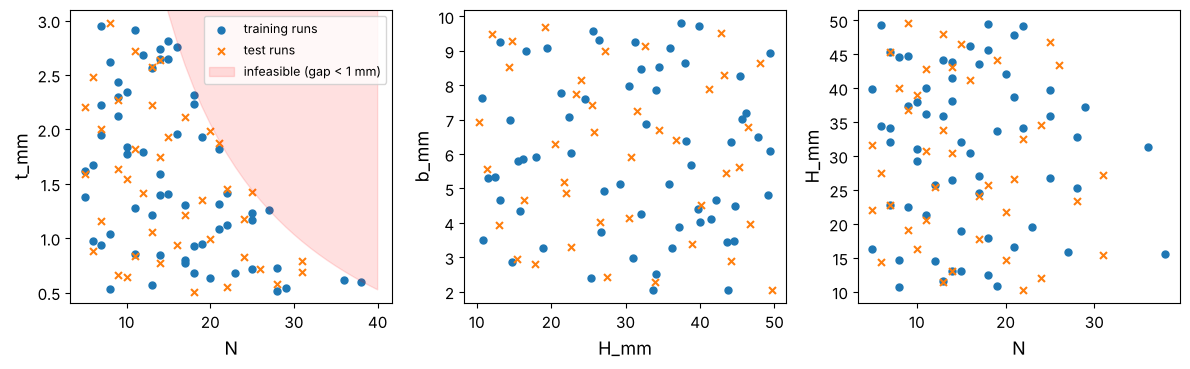

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
pairs = [("N", "t_mm"), ("H_mm", "b_mm"), ("N", "H_mm")]
NN = np.arange(5, 41)
for ax, (a, b) in zip(axes, pairs):
    ax.scatter(train_runs[a], train_runs[b], c="C0", s=25, label="training runs")
    ax.scatter(test_runs[a], test_runs[b], c="C1", marker="x", s=25, label="test runs")
    if (a, b) == ("N", "t_mm"):
        ax.fill_between(NN, (W * 1e3 - (NN - 1) * S_MIN) / NN, 3.2, color="red", alpha=0.12,
                        label="infeasible (gap < 1 mm)")
        ax.set_ylim(0.4, 3.1)
    ax.set_xlabel(a); ax.set_ylabel(b)
axes[0].legend(fontsize=9)
save_fig("design_plot")
plt.show()

Saving figure scatter_inputs_plot


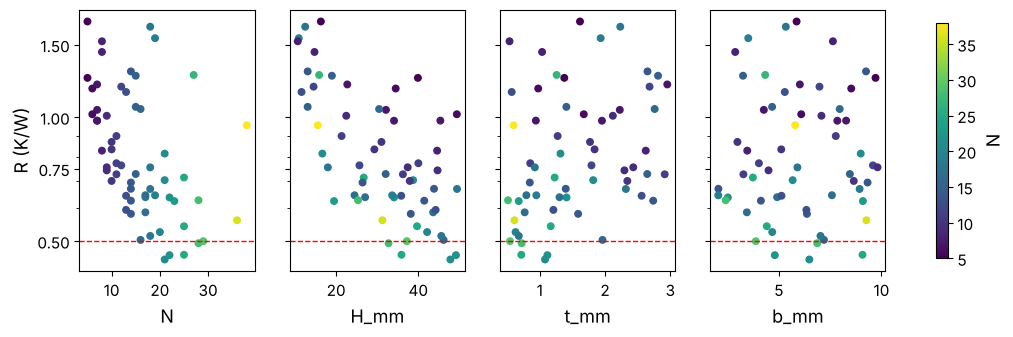

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, v in zip(axes, VARS):
    sc = ax.scatter(train_runs[v], train_runs.R, c=train_runs.N, cmap="viridis", s=22)
    ax.set_xlabel(v)
    ax.axhline(R_MAX, color="red", ls="--", lw=1)
axes[0].set_ylabel("R (K/W)")
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
axes[0].yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
axes[0].set_yticks([0.5, 0.75, 1.0, 1.5])
fig.colorbar(sc, ax=axes, label="N", shrink=0.9)
save_fig("scatter_inputs_plot", tight_layout=False)
plt.show()

In [19]:
corr_df = train_runs[VARS + ["U", "h", "R_1d", "R"]].copy()
corr_df["log_R"] = np.log(corr_df.R)
corr_df.corr(method="spearman")["log_R"].drop(["R", "log_R"]).sort_values()

H_mm   -0.611336
N      -0.561832
b_mm    0.023784
h       0.231231
U       0.293470
t_mm    0.354654
R_1d    0.984551
Name: log_R, dtype: float64

Saving figure fin_sweep_plot


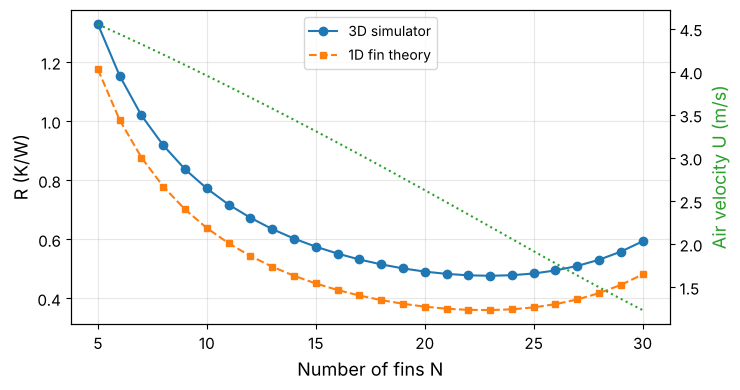

Best N for H=40, t=1, b=6: 23
Air velocity: 4.6 m/s with 5 fins, 1.2 m/s with 30 fins


In [20]:
# A one-at-a-time sweep: vary the number of fins, keep everything else fixed
sweep = run(np.array([[n_, 40.0, 1.0, 6.0] for n_ in range(5, 31)]))
fig, ax1 = plt.subplots(figsize=(7.5, 4))
ax1.plot(sweep.N, sweep.R, "o-", label="3D simulator")
ax1.plot(sweep.N, sweep.R_1d, "s--", ms=4, label="1D fin theory")
ax1.set_xlabel("Number of fins N"); ax1.set_ylabel("R (K/W)")
ax2 = ax1.twinx()
ax2.plot(sweep.N, sweep.U, "C2:", label="air velocity")
ax2.set_ylabel("Air velocity U (m/s)", color="C2")
ax1.legend(loc="upper center")
ax1.grid(True, alpha=0.3)
save_fig("fin_sweep_plot")
plt.show()
print("Best N for H=40, t=1, b=6:", int(sweep.N[sweep.R.idxmin()]))
print(f"Air velocity: {sweep.U.iloc[0]:.1f} m/s with 5 fins, {sweep.U.iloc[-1]:.1f} m/s with 30 fins")

Saving figure fan_curve_plot


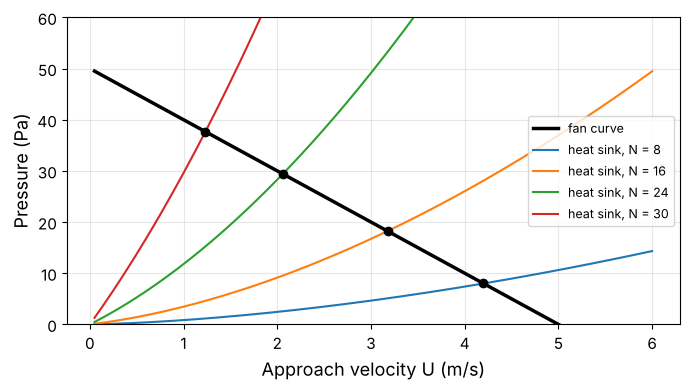

In [21]:
U_grid = np.linspace(0.05, 6, 200)
plt.figure(figsize=(7, 4))
plt.plot(U_grid, FAN_P0 * (1 - U_grid * W * 0.040 / FAN_VMAX), "k-", lw=2.5, label="fan curve")
for n_ in (8, 16, 24, 30):
    s_ = fin_spacing(n_, 0.001); sig = 1 - n_ * 0.001 / W
    def dp_(U):
        Uc = U / sig; Re = Uc * 2 * s_ / NU_AIR
        f_app = np.sqrt((3.44 / np.sqrt(L / (2 * s_ * Re))) ** 2 + 24 ** 2) / Re
        return (4 * f_app * L / (2 * s_) + 0.42 * (1 - sig ** 2) + (1 - sig ** 2) ** 2) * 0.5 * RHO_AIR * Uc ** 2
    plt.plot(U_grid, dp_(U_grid), label=f"heat sink, N = {n_}")
    fo = channel_flow(n_, 0.040, 0.001)
    plt.plot(fo["U"], fo["dp"], "ko")
plt.ylim(0, 60)
plt.xlabel("Approach velocity U (m/s)"); plt.ylabel("Pressure (Pa)")
plt.legend(fontsize=9)
plt.grid(True, alpha=0.3)
save_fig("fan_curve_plot")
plt.show()

## Prepare the Data

Saving figure log_transform_plot


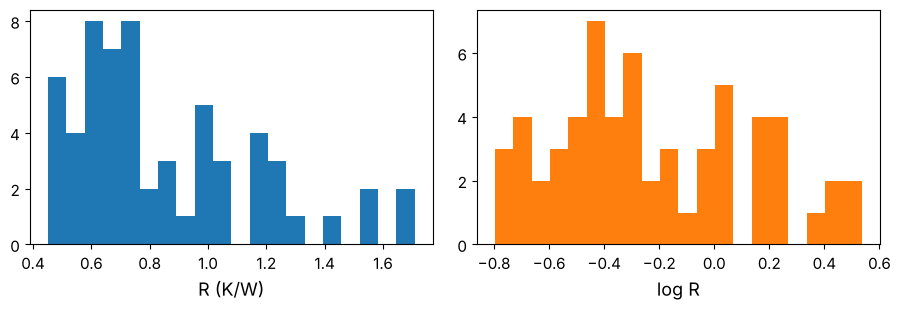

In [22]:
X_train = train_runs[VARS].values
y_train = np.log(train_runs.R.values)        # we model log R
X_test = test_runs[VARS].values
y_test = np.log(test_runs.R.values)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(train_runs.R, bins=20); axes[0].set_xlabel("R (K/W)")
axes[1].hist(y_train, bins=20, color="C1"); axes[1].set_xlabel("log R")
save_fig("log_transform_plot")
plt.show()

In [23]:
from sklearn.base import BaseEstimator, TransformerMixin

class HeatSinkFeatures(BaseEstimator, TransformerMixin):
    """Adds physics-based features: the gap between fins, the total fin area,
    and the prediction of 1D fin theory (log R_1d)."""
    def __init__(self, add_fin_theory=True):
        self.add_fin_theory = add_fin_theory
    def fit(self, X, y=None):
        return self
    def __sklearn_is_fitted__(self):
        return True
    def transform(self, X):
        N, H, t, b = X.T
        gap = (W * 1e3 - N * t) / (N - 1)
        area = N * 2 * H                            # fin area per mm of depth
        feats = [X, gap[:, None], np.log(area)[:, None]]
        if self.add_fin_theory:
            r1 = [fin_theory(int(round(n)), h / 1e3, tt / 1e3, bb / 1e3) for n, h, tt, bb in X]
            feats.append(np.log(r1)[:, None])
        return np.hstack(feats)

HeatSinkFeatures().transform(X_train[:3]).round(3)

array([[ 8.   , 14.726,  1.036,  2.874,  7.388,  5.462,  0.185],
       [12.   , 25.672,  1.792,  9.586,  3.5  ,  6.423, -0.404],
       [23.   , 19.486,  0.678,  9.095,  2.018,  6.798, -0.642]])

## Select and Train a Model

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, RBF, ConstantKernel as C, WhiteKernel

def make_gp(nu=2.5, n_dims=4):
    kernel = (C(1.0, (1e-2, 1e2)) * Matern(length_scale=np.ones(n_dims), length_scale_bounds=(1e-2, 1e2), nu=nu)
              + WhiteKernel(1e-6, (1e-10, 1e-3)))
    return GaussianProcessRegressor(kernel, normalize_y=True, n_restarts_optimizer=5, random_state=42)

models = {
    "Linear regression": make_pipeline(MinMaxScaler(), LinearRegression()),
    "Quadratic response surface": make_pipeline(MinMaxScaler(), PolynomialFeatures(2), Ridge(1e-3)),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gaussian process": make_pipeline(MinMaxScaler(), make_gp()),
}
lin = models["Linear regression"].fit(X_train, y_train)
pred = np.exp(lin.predict(X_train))
print("Linear model, training error: "
      f"{100 * np.sqrt(np.mean((pred / train_runs.R - 1) ** 2)):.1f}% (relative RMSE)")

Linear model, training error: 17.8% (relative RMSE)


In [25]:
from sklearn.model_selection import KFold, cross_val_predict

def rel_rmse(y_log, pred_log):
    """Relative RMSE on R, in %: the error measure we chose in the problem framing."""
    return 100 * np.sqrt(np.mean((np.exp(pred_log - y_log) - 1) ** 2))

cv = KFold(n_splits=10, shuffle=True, random_state=42)
cv_results = {}
for name, model in models.items():
    p = cross_val_predict(model, X_train, y_train, cv=cv)
    cv_results[name] = rel_rmse(y_train, p)
pd.Series(cv_results, name="10-fold CV relative RMSE (%)").round(2)

Linear regression             19.38
Quadratic response surface    12.74
Random forest                 16.90
Gaussian process              10.43
Name: 10-fold CV relative RMSE (%), dtype: float64

In [26]:
# The same models, fed with the physics-based features
models_phys = {name + " + physics features": make_pipeline(HeatSinkFeatures(), *(
    [m] if name == "Random forest" else list(m.named_steps.values()))) for name, m in models.items()}
models_phys["Gaussian process + physics features"] = make_pipeline(HeatSinkFeatures(), MinMaxScaler(), make_gp(n_dims=7))
for name, model in models_phys.items():
    p = cross_val_predict(model, X_train, y_train, cv=cv)
    cv_results[name] = rel_rmse(y_train, p)
pd.Series(cv_results, name="10-fold CV relative RMSE (%)").round(2).sort_values()

Gaussian process + physics features               0.36
Quadratic response surface + physics features     1.35
Linear regression + physics features              3.07
Random forest + physics features                  5.64
Gaussian process                                 10.43
Quadratic response surface                       12.74
Random forest                                    16.90
Linear regression                                19.38
Name: 10-fold CV relative RMSE (%), dtype: float64

Saving figure learning_curves_plot


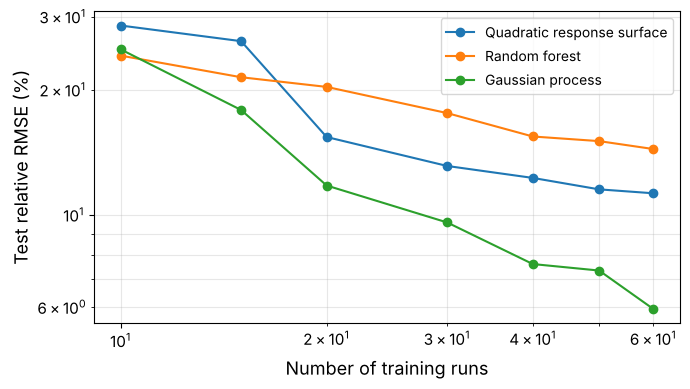

In [27]:
sizes = [10, 15, 20, 30, 40, 50, 60]
lc = {name: [] for name in ["Quadratic response surface", "Random forest", "Gaussian process"]}
rng = np.random.default_rng(0)
for n_ in sizes:
    for name in lc:
        errs = []
        for rep in range(5):
            sub = rng.choice(len(X_train), n_, replace=False)
            m = sklearn.base.clone(models[name]).fit(X_train[sub], y_train[sub])
            errs.append(rel_rmse(y_test, m.predict(X_test)))
        lc[name].append(np.median(errs))
plt.figure(figsize=(7, 4))
for name, errs in lc.items():
    plt.loglog(sizes, errs, "o-", label=name)
plt.xlabel("Number of training runs")
plt.ylabel("Test relative RMSE (%)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
save_fig("learning_curves_plot")
plt.show()

## Fine-Tune Your Model

In [28]:
from sklearn.model_selection import GridSearchCV

def kernel_list(n_dims):
    out = []
    for nu in (0.5, 1.5, 2.5, np.inf):
        base = (RBF(np.ones(n_dims), (1e-2, 1e2)) if nu == np.inf
                else Matern(np.ones(n_dims), (1e-2, 1e2), nu=nu))
        out.append(C(1.0, (1e-2, 1e2)) * base + WhiteKernel(1e-6, (1e-10, 1e-3)))
    return out

pipe = make_pipeline(HeatSinkFeatures(), MinMaxScaler(), make_gp(n_dims=7))
param_grid = [
    {"heatsinkfeatures__add_fin_theory": [True], "gaussianprocessregressor__kernel": kernel_list(7)},
    {"heatsinkfeatures__add_fin_theory": [False], "gaussianprocessregressor__kernel": kernel_list(6)},
]
grid_search = GridSearchCV(pipe, param_grid, cv=cv, scoring="neg_root_mean_squared_error")
grid_search.fit(X_train, y_train)
kernel_names = ["Matérn 1/2", "Matérn 3/2", "Matérn 5/2", "RBF"]
pd.DataFrame({"fin theory feature": [p["heatsinkfeatures__add_fin_theory"] for p in grid_search.cv_results_["params"]],
              "kernel (ARD)": kernel_names * 2,
              "CV RMSE of log R": -grid_search.cv_results_["mean_test_score"]}).round(4)

,fin theory feature,kernel (ARD),CV RMSE of log R
0,True,Matérn 1/2,0.0167
1,True,Matérn 3/2,0.0054
2,True,Matérn 5/2,0.0029
3,True,RBF,0.0040
4,False,Matérn 1/2,0.0590
5,False,Matérn 3/2,0.0401
6,False,Matérn 5/2,0.0475
7,False,RBF,0.0471


In [29]:
final_model = grid_search.best_estimator_
gp = final_model[-1]
print(gp.kernel_)
print(f"log marginal likelihood: {gp.log_marginal_likelihood_value_:.1f}")
FEATURES = VARS + ["gap", "log_fin_area", "log_R_1d"]
ell = gp.kernel_.k1.k2.length_scale
pd.Series(1 / ell, index=FEATURES, name="1 / length scale (relevance)").round(2)

7.76**2 * Matern(length_scale=[7.92, 100, 12.1, 3.81, 100, 100, 8.07], nu=2.5) + WhiteKernel(noise_level=1.77e-06)
log marginal likelihood: 131.9


N               0.13
H_mm            0.01
t_mm            0.08
b_mm            0.26
gap             0.01
log_fin_area    0.01
log_R_1d        0.12
Name: 1 / length scale (relevance), dtype: float64

In [30]:
# Global sensitivity analysis on the surrogate (Saltelli / Jansen estimators)
def sobol_indices(f, n=20000, seed=0):
    rng = np.random.default_rng(seed)
    def draw(m):
        out = []
        while len(out) < m:
            X = LOWER + rng.random((m, 4)) * (UPPER - LOWER)
            X[:, 0] = np.round(X[:, 0])
            out += list(X[is_feasible(X)])
        return np.array(out[:m])
    A, B = draw(n), draw(n)
    fA, fB = f(A), f(B)
    var = np.var(np.concatenate([fA, fB]))
    S1, ST = [], []
    for i in range(4):
        AB = A.copy(); AB[:, i] = B[:, i]
        ok = is_feasible(AB)                 # discard mixed points outside the feasible region
        fAB = f(AB[ok])
        S1.append(np.mean(fB[ok] * (fAB - fA[ok])) / var)
        ST.append(0.5 * np.mean((fA[ok] - fAB) ** 2) / var)
    return pd.DataFrame({"first order S_i": S1, "total S_Ti": ST}, index=VARS)

sobol = sobol_indices(final_model.predict)
sobol.round(3)

,first order S_i,total S_Ti
N,0.350,0.508
H_mm,0.456,0.464
t_mm,0.029,0.079
b_mm,0.014,0.018


Saving figure multifidelity_plot


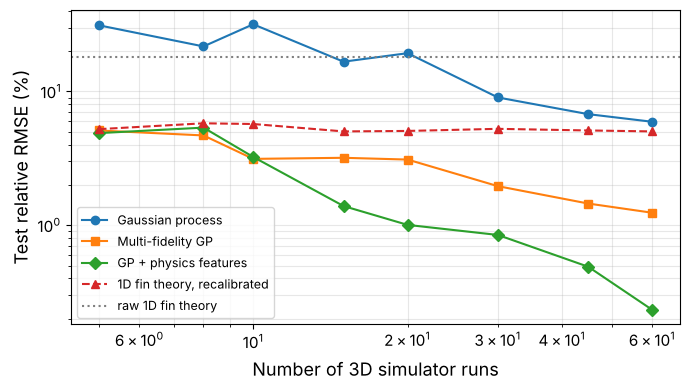

,Gaussian process,Multi-fidelity GP,GP + physics features,"1D fin theory, recalibrated"
5,31.25,5.11,4.88,5.23
8,21.71,4.69,5.37,5.78
10,31.79,3.13,3.24,5.71
15,16.70,3.19,1.39,5.03
20,19.33,3.10,1.01,5.07
30,9.02,1.96,0.85,5.26
45,6.77,1.45,0.49,5.11
60,5.94,1.24,0.23,5.03


In [31]:
class MultiFidelityGP(BaseEstimator):
    """y_high(x) ≈ rho * y_low(x) + c + delta(x): a GP models what the 1D theory gets wrong
    (a simple version of Kennedy & O'Hagan's autoregressive multi-fidelity model)."""
    def __init__(self, nu=2.5):
        self.nu = nu
    def _low(self, X):
        return np.log([fin_theory(int(round(n)), h / 1e3, t / 1e3, b / 1e3) for n, h, t, b in X])
    def fit(self, X, y):
        lo = self._low(X)
        self.rho_, self.c_ = np.polyfit(lo, y, 1)
        self.scaler_ = MinMaxScaler().fit(np.vstack([LOWER, UPPER]))
        self.gp_ = make_gp(self.nu).fit(self.scaler_.transform(X), y - self.rho_ * lo - self.c_)
        return self
    def predict(self, X, return_std=False):
        lo = self._low(X)
        d = self.gp_.predict(self.scaler_.transform(X), return_std=return_std)
        if return_std:
            return self.rho_ * lo + self.c_ + d[0], d[1]
        return self.rho_ * lo + self.c_ + d

mf_sizes = [5, 8, 10, 15, 20, 30, 45, 60]
contenders = {"Gaussian process": lambda: sklearn.base.clone(models["Gaussian process"]),
              "Multi-fidelity GP": MultiFidelityGP,
              "GP + physics features": lambda: sklearn.base.clone(final_model)}
lc_mf = {k: [] for k in list(contenders) + ["1D fin theory, recalibrated"]}
for n_ in mf_sizes:
    errs = {k: [] for k in lc_mf}
    for rep in range(5):
        sub = rng.choice(len(X_train), n_, replace=False)
        for k, make in contenders.items():
            errs[k].append(rel_rmse(y_test, make().fit(X_train[sub], y_train[sub]).predict(X_test)))
        lo_sub = np.log(train_runs.R_1d.values[sub])
        rho, c0 = np.polyfit(lo_sub, y_train[sub], 1)
        errs["1D fin theory, recalibrated"].append(rel_rmse(y_test, rho * np.log(test_runs.R_1d.values) + c0))
    for k in lc_mf:
        lc_mf[k].append(np.median(errs[k]))
plt.figure(figsize=(7, 4))
for (k, v), st in zip(lc_mf.items(), ["o-", "s-", "D-", "^--"]):
    plt.loglog(mf_sizes, v, st, label=k)
plt.axhline(rel_rmse(y_test, np.log(test_runs.R_1d.values)), color="gray", ls=":", label="raw 1D fin theory")
plt.xlabel("Number of 3D simulator runs")
plt.ylabel("Test relative RMSE (%)")
plt.legend(fontsize=9)
plt.grid(True, which="both", alpha=0.3)
save_fig("multifidelity_plot")
plt.show()
pd.DataFrame(lc_mf, index=mf_sizes).round(2)

In [32]:
gp_model = sklearn.base.clone(models["Gaussian process"]).fit(X_train, y_train)
mf_model = MultiFidelityGP().fit(X_train, y_train)
test_preds = {name: m.predict(X_test, return_std=True) for name, m in
              (("GP", gp_model), ("Multi-fidelity GP", mf_model), ("GP + physics features", final_model))}
print(f"log marginal likelihood of the raw-input GP: {gp_model[-1].log_marginal_likelihood_value_:.1f}")
print(f"raw 1D fin theory: test relative RMSE {rel_rmse(y_test, np.log(test_runs.R_1d.values)):.1f}%")
for name, (m_, s_) in test_preds.items():
    inside = np.mean(np.abs(y_test - m_) <= 1.96 * s_)
    print(f"{name:22s} test relative RMSE {rel_rmse(y_test, m_):.2f}%, "
          f"worst {100 * np.max(np.abs(np.exp(m_ - y_test) - 1)):.1f}%, 95% coverage {inside:.0%}")

log marginal likelihood of the raw-input GP: -23.2
raw 1D fin theory: test relative RMSE 18.0%
GP                     test relative RMSE 5.94%, worst 18.8%, 95% coverage 95%
Multi-fidelity GP      test relative RMSE 1.24%, worst 5.3%, 95% coverage 92%
GP + physics features  test relative RMSE 0.23%, worst 1.3%, 95% coverage 98%


Saving figure parity_plot


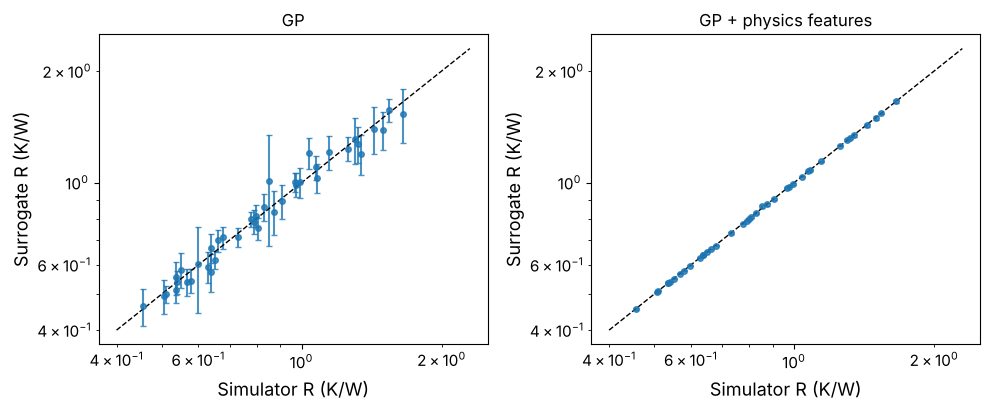

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, name in zip(axes, ("GP", "GP + physics features")):
    m_, s_ = test_preds[name]
    ax.errorbar(test_runs.R, np.exp(m_), yerr=1.96 * s_ * np.exp(m_), fmt="o", ms=4, capsize=2, alpha=0.8)
    lim = [0.4, 2.3]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Simulator R (K/W)"); ax.set_ylabel("Surrogate R (K/W)")
    ax.set_title(name)
save_fig("parity_plot")
plt.show()

## Use the Surrogate: Find the Lightest Heat Sink That Keeps the Chip Cool

In [34]:
def mass_g(X):
    """The heat sink's mass in grams: a formula, so it needs no surrogate."""
    X = np.atleast_2d(X)
    N, H, t, b = X.T
    return RHO_AL * (W * 1e3 * b + N * t * H) * L * 1e3 * 1e-9 * 1e3

mass_g(X_train[:3]).round(1)

array([ 47.7, 182.6, 137.6])

In [35]:
from scipy.optimize import differential_evolution, NonlinearConstraint

def surrogate_constraint(x, z=2.0, model=final_model):
    if not is_feasible(x)[0]:
        return 10.0                         # no gap between the fins: reject (the 2nd constraint)
    m_, s_ = model.predict(np.atleast_2d(x), return_std=True)
    return np.exp(m_ + z * s_)[0]           # a cautious (upper-bound) estimate of R

constraints = [NonlinearConstraint(surrogate_constraint, 0, R_MAX),
               NonlinearConstraint(lambda x: (W * 1e3 - round(x[0]) * x[2]) / (round(x[0]) - 1), S_MIN, np.inf)]
t0 = time.time()
res = differential_evolution(lambda x: mass_g(x)[0], bounds=list(zip(LOWER, UPPER)),
                             constraints=constraints, integrality=[True, False, False, False],
                             seed=42, tol=1e-6, maxiter=200, polish=False)
x_sur = res.x
print(f"Surrogate optimum: N={x_sur[0]:.0f}, H={x_sur[1]:.1f} mm, t={x_sur[2]:.2f} mm, b={x_sur[3]:.2f} mm,"
      f" mass {res.fun:.1f} g ({res.nfev} evaluations in {time.time() - t0:.0f} s)")
r_check = heat_sink_sim(x_sur[0], x_sur[1] / 1e3, x_sur[2] / 1e3, x_sur[3] / 1e3)
print(f"Simulator check: R = {r_check:.4f} K/W (limit {R_MAX}) -> chip at {T_AIR + Q * r_check:.1f} °C")
print(f"The same search on the simulator would have taken ~{res.nfev * sim_time / 60:.0f} minutes"
      f" ({res.nfev / 24:.0f} days of CFD at 1 hour per run)")

Surrogate optimum: N=27, H=35.8 mm, t=0.50 mm, b=4.51 mm, mass 122.1 g (2961 evaluations in 5 s)


Simulator check: R = 0.4988 K/W (limit 0.5) -> chip at 84.9 °C
The same search on the simulator would have taken ~13 minutes (123 days of CFD at 1 hour per run)


In [36]:
from scipy.stats import norm

def candidates(n, seed):
    return sample_designs(n, seed=seed, method="sobol")

def constrained_bo(X0, y0, n_iter=25, seed=0):
    """Bayesian optimization when the objective (mass) is cheap but the constraint (R) is expensive:
    maximize the improvement in mass times the probability that the constraint is satisfied."""
    X, y = X0.copy(), y0.copy()
    for it in range(n_iter):
        model = sklearn.base.clone(final_model).fit(X, y)
        feasible = y <= np.log(R_MAX)
        best = mass_g(X[feasible]).min() if feasible.any() else mass_g(X).max()
        C_ = candidates(4096, seed=1000 * seed + it)
        m_, s_ = model.predict(C_, return_std=True)
        pof = norm.cdf((np.log(R_MAX) - m_) / s_)                 # probability of feasibility
        acq = np.maximum(best - mass_g(C_), 0) * pof
        x_new = C_[np.argmax(acq)]
        y_new = np.log(heat_sink_sim(x_new[0], x_new[1] / 1e3, x_new[2] / 1e3, x_new[3] / 1e3))
        X, y = np.vstack([X, x_new]), np.append(y, y_new)
    return X, y

def best_feasible_trace(X, y):
    m = np.where(y <= np.log(R_MAX), mass_g(X), np.inf)
    return np.minimum.accumulate(m)

X0 = sample_designs(15, seed=3)
y0 = np.log([heat_sink_sim(a, b_ / 1e3, c / 1e3, d / 1e3) for a, b_, c, d in X0])
t0 = time.time()
X_bo, y_bo = constrained_bo(X0, y0, n_iter=25)
print(f"BO: 15 initial + 25 adaptive runs in {time.time() - t0:.0f} s")
i_best = np.argmin(np.where(y_bo <= np.log(R_MAX), mass_g(X_bo), np.inf))
x_bo = X_bo[i_best]
print(f"Best verified design: N={x_bo[0]:.0f}, H={x_bo[1]:.1f} mm, t={x_bo[2]:.2f} mm, b={x_bo[3]:.2f} mm,"
      f" mass {mass_g(x_bo)[0]:.1f} g, R = {np.exp(y_bo[i_best]):.4f} K/W (run #{i_best + 1})")

BO: 15 initial + 25 adaptive runs in 124 s
Best verified design: N=25, H=37.1 mm, t=0.53 mm, b=4.81 mm, mass 126.2 g, R = 0.4977 K/W (run #38)


Saving figure bo_vs_random_plot


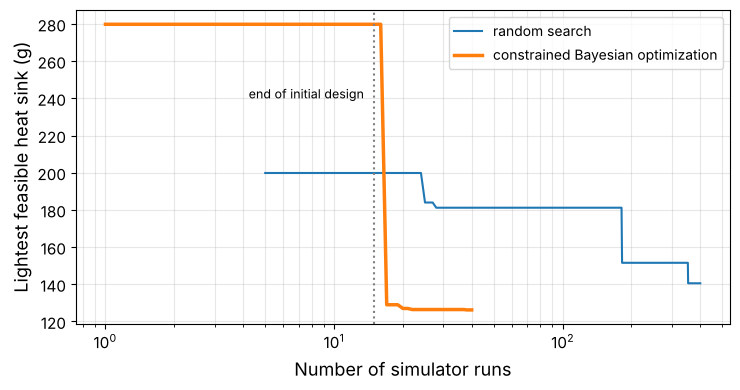

BO after  16 runs: 279.8 g
BO after  17 runs: 129.0 g
BO after  20 runs: 127.0 g
BO after  30 runs: 126.4 g
BO after  40 runs: 126.2 g
random search after  40 runs: 181.2 g
random search after 100 runs: 181.2 g
random search after 400 runs: 140.5 g


In [37]:
X_rand = sample_designs(400, seed=11)
y_rand = np.log([heat_sink_sim(a, b_ / 1e3, c / 1e3, d / 1e3) for a, b_, c, d in X_rand])
trace_bo = best_feasible_trace(X_bo, y_bo)
trace_rand = best_feasible_trace(X_rand, y_rand)
plt.figure(figsize=(7.5, 4))
plt.semilogx(np.arange(1, len(trace_rand) + 1), trace_rand, label="random search")
plt.semilogx(np.arange(1, len(trace_bo) + 1), trace_bo, lw=2.5, label="constrained Bayesian optimization")
plt.axvline(15, color="gray", ls=":")
plt.text(14, 240, "end of initial design ", fontsize=9, ha="right")
plt.xlabel("Number of simulator runs"); plt.ylabel("Lightest feasible heat sink (g)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
save_fig("bo_vs_random_plot")
plt.show()
for k in (16, 17, 20, 30, 40):
    print(f"BO after {k:3d} runs: {trace_bo[k - 1]:.1f} g")
for k in (40, 100, 400):
    print(f"random search after {k:3d} runs: {trace_rand[k - 1]:.1f} g")

Saving figure pareto_plot


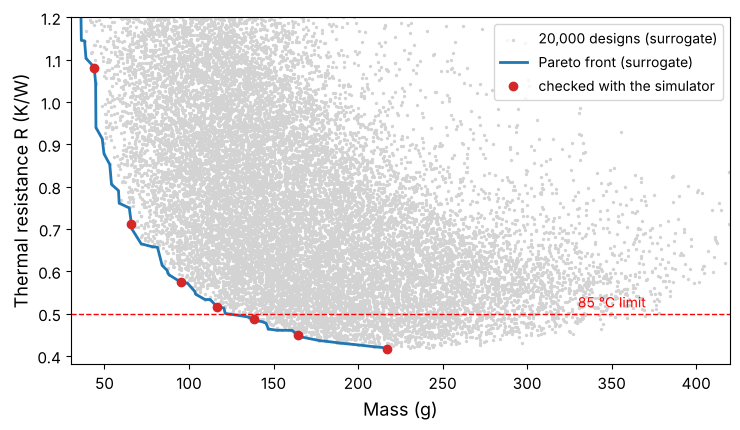

max relative error on the checked front points: 0.5%


In [38]:
# The trade-off between mass and thermal resistance, explored on the surrogate
final_model2 = sklearn.base.clone(final_model).fit(np.vstack([X_train, X_bo]), np.append(y_train, y_bo))
C_ = sample_designs(20000, seed=5, method="sobol")
R_pred = np.exp(final_model2.predict(C_))
M_ = mass_g(C_)
order = np.argsort(M_)
front = order[np.r_[True, np.diff(np.minimum.accumulate(R_pred[order])) < 0]]
front = front[np.argsort(M_[front])]
pick = front[np.linspace(0, len(front) - 1, 8).astype(int)]
R_pick = np.array([heat_sink_sim(a, b_ / 1e3, c / 1e3, d / 1e3) for a, b_, c, d in C_[pick]])
plt.figure(figsize=(7.5, 4.4))
plt.scatter(M_, R_pred, s=2, c="lightgray", label="20,000 designs (surrogate)")
plt.plot(M_[front], R_pred[front], "C0-", lw=2, label="Pareto front (surrogate)")
plt.plot(M_[pick], R_pick, "C3o", label="checked with the simulator")
plt.axhline(R_MAX, color="red", ls="--", lw=1)
plt.text(330, R_MAX * 1.03, "85 °C limit", color="red")
plt.ylim(0.38, 1.2); plt.xlim(30, 420)
plt.xlabel("Mass (g)"); plt.ylabel("Thermal resistance R (K/W)")
plt.legend()
save_fig("pareto_plot")
plt.show()
print("max relative error on the checked front points:",
      f"{100 * np.max(np.abs(R_pred[pick] / R_pick - 1)):.1f}%")

## Present Your Solution

In [39]:
best_runs = pd.DataFrame([dict(design="BO (verified)", N=int(x_bo[0]), H_mm=x_bo[1], t_mm=x_bo[2], b_mm=x_bo[3],
                               mass_g=mass_g(x_bo)[0], R=np.exp(y_bo[i_best])),
                          dict(design="DE on surrogate (verified)", N=int(x_sur[0]), H_mm=x_sur[1], t_mm=x_sur[2],
                               b_mm=x_sur[3], mass_g=res.fun, R=r_check)])
best_runs["T_chip_C"] = T_AIR + Q * best_runs.R
for col in ("U", "dp", "Re"):
    best_runs[col] = [channel_flow(int(r.N), r.H_mm / 1e3, r.t_mm / 1e3)[col] for r in best_runs.itertuples()]
best_runs.round(2)

,design,N,H_mm,t_mm,b_mm,mass_g,R,T_chip_C,U,dp,Re
0,BO (verified),25,37.14,0.53,4.81,126.20,0.5,84.77,2.95,22.62,893.42
1,DE on surrogate (verified),27,35.76,0.50,4.51,122.07,0.5,84.88,2.85,24.52,797.24


In [40]:
# For comparison: the team's current method, 1D fin theory with a 30% safety margin
res_1d = differential_evolution(lambda x: mass_g(x)[0], bounds=list(zip(LOWER, UPPER)),
                                constraints=[NonlinearConstraint(lambda x: 1.3 * fin_theory(int(round(x[0])), x[1] / 1e3, x[2] / 1e3, x[3] / 1e3)
                                                                 if is_feasible(x)[0] else 10.0, 0, R_MAX)],
                                integrality=[True, False, False, False], seed=42, tol=1e-6, maxiter=200, polish=False)
x_1d = res_1d.x
r_1d_check = heat_sink_sim(x_1d[0], x_1d[1] / 1e3, x_1d[2] / 1e3, x_1d[3] / 1e3)
print(f"1D + 30% margin: N={x_1d[0]:.0f}, H={x_1d[1]:.1f} mm, t={x_1d[2]:.2f} mm, b={x_1d[3]:.2f} mm, "
      f"mass {res_1d.fun:.1f} g -> simulator: chip at {T_AIR + Q * r_1d_check:.1f} °C")
x_1d0 = differential_evolution(lambda x: mass_g(x)[0], bounds=list(zip(LOWER, UPPER)),
                               constraints=[NonlinearConstraint(lambda x: fin_theory(int(round(x[0])), x[1] / 1e3, x[2] / 1e3, x[3] / 1e3)
                                                                if is_feasible(x)[0] else 10.0, 0, R_MAX)],
                               integrality=[True, False, False, False], seed=42, tol=1e-6, maxiter=200, polish=False)
r_1d0 = heat_sink_sim(x_1d0.x[0], x_1d0.x[1] / 1e3, x_1d0.x[2] / 1e3, x_1d0.x[3] / 1e3)
print(f"1D, no margin:   mass {x_1d0.fun:.1f} g -> simulator: chip at {T_AIR + Q * r_1d0:.1f} °C")

1D + 30% margin: N=25, H=30.4 mm, t=0.50 mm, b=2.00 mm, mass 81.0 g -> simulator: chip at 98.9 °C


1D, no margin:   mass 56.5 g -> simulator: chip at 112.0 °C


Saving figure optimized_design_plot


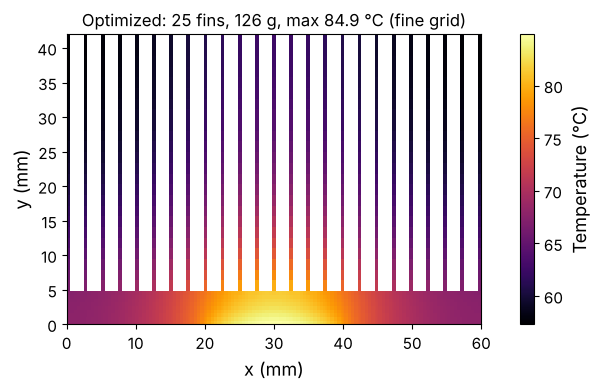

In [41]:
x_fin = x_bo
R_fin, info = heat_sink_sim(x_fin[0], x_fin[1] / 1e3, x_fin[2] / 1e3, x_fin[3] / 1e3, full_output=True,
                            nf=3, ng=4, nb=9, nh=24, nz=36)
T = np.full(info["solid"].shape, np.nan)
T[info["solid"]] = T_AIR + info["theta"] + Q / (2 * info["mdot"] * CP_AIR)
plt.figure(figsize=(8, 4))
plt.pcolormesh(info["xe"] * 1e3, info["ye"] * 1e3, T[:, T.shape[1] // 2, :], cmap="inferno")
plt.colorbar(label="Temperature (°C)")
plt.gca().set_aspect("equal")
plt.xlabel("x (mm)"); plt.ylabel("y (mm)")
plt.title(f"Optimized: {x_fin[0]:.0f} fins, {mass_g(x_fin)[0]:.0f} g, max {np.nanmax(T):.1f} °C (fine grid)")
save_fig("optimized_design_plot")
plt.show()

## Launch, Monitor, and Maintain

In [42]:
import joblib

class HeatSinkSurrogate:
    """What we ship: the surrogate plus its validity domain."""
    def __init__(self, model):
        self.model = model
    def predict(self, X, return_std=False):
        X = np.atleast_2d(X)
        outside = np.any((X < LOWER) | (X > UPPER), axis=1) | ~is_feasible(X)
        if outside.any():
            raise ValueError(f"{outside.sum()} design(s) outside the validated domain")
        m_, s_ = self.model.predict(X, return_std=True)
        return (np.exp(m_), np.exp(m_) * s_) if return_std else np.exp(m_)

surrogate = HeatSinkSurrogate(final_model2)
joblib.dump(surrogate, "heat_sink_surrogate.pkl")
t0 = time.time()
r_, s_ = surrogate.predict([[20, 40, 1.0, 6.0]], return_std=True)
print(f"R = {r_[0]:.4f} ± {1.96 * s_[0]:.4f} K/W in {1e3 * (time.time() - t0):.1f} ms")
try:
    surrogate.predict([[20, 70, 1.0, 6.0]])
except ValueError as e:
    print("Refused:", e)

R = 0.4905 ± 0.0004 K/W in 1.2 ms
Refused: 1 design(s) outside the validated domain


In [43]:
import json
os.makedirs("animations", exist_ok=True)
feats, scaler, gpr = final_model2.named_steps.values()
X_all = np.vstack([X_train, X_bo])
Xs = scaler.transform(feats.transform(X_all))
k_ = gpr.kernel_
anim = dict(
    X=Xs.tolist(),
    alpha=gpr.alpha_.ravel().tolist(),
    y_mean=float(gpr._y_train_mean), y_std=float(gpr._y_train_std),
    amp=float(k_.k1.k1.constant_value), ell=k_.k1.k2.length_scale.tolist(), nu=float(k_.k1.k2.nu),
    noise=float(k_.k2.noise_level),
    L_inv=np.linalg.inv(gpr.L_).tolist(),
    s_min=scaler.data_min_.tolist(), s_range=scaler.data_range_.tolist(),
    lower=LOWER.tolist(), upper=UPPER.tolist(),
    runs=[dict(m=round(float(m), 2), r=round(float(np.exp(v)), 4)) for m, v in
          zip(mass_g(X_all), np.append(y_train, y_bo))],
    front=[[round(float(M_[i]), 2), round(float(R_pred[i]), 4)] for i in front],
    trace_bo=[None if not np.isfinite(v) else round(float(v), 2) for v in trace_bo],
    trace_rand=[None if not np.isfinite(v) else round(float(v), 2) for v in trace_rand[:100]],
    bo_runs=[dict(m=round(float(mass_g(x)[0]), 2), r=round(float(np.exp(v)), 4)) for x, v in zip(X_bo, y_bo)],
    best=dict(N=int(x_bo[0]), H=float(x_bo[1]), t=float(x_bo[2]), b=float(x_bo[3])),
    const=dict(W=W, L=L, Q=Q, T_air=T_AIR, T_max=T_MAX, k_al=K_AL, rho_al=RHO_AL, k_air=K_AIR,
               nu=NU_AIR, pr=PR_AIR, rho_air=RHO_AIR, cp=CP_AIR, p0=FAN_P0, vmax=FAN_VMAX))
with open(os.path.join("animations", "data.json"), "w") as f:
    json.dump(anim, f)
print("exported", len(anim["X"]), "training points")

exported 100 training points
